# Exploração PETR4.SA

Notebook acadêmico da entrega FIAP (Fase 4). Serve para **mostrar a série e o split temporal** no vídeo/relatório.

A coleta e a limpeza vêm de `src.data`. O treino oficial **não** é este notebook: use `uv run python -m src.model.train`. A previsão em produção é a API FastAPI.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd()
if not (ROOT / "src").exists() and (ROOT.parent / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.data import collect_prices, clean_series, chronological_split
from src.settings import TICKER, START_DATE

print("raiz:", ROOT)
print("ticker:", TICKER, "início:", START_DATE)

raiz: /Users/cristiano.oloiveira/www/github/pos-machine-learning-fiap/grupo-98-tech-challenger-fase4
ticker: PETR4.SA início: 2018-01-01


## Série histórica

`collect_prices` usa yfinance na primeira vez e grava cache em `data/raw.parquet`. Nas próximas execuções lê o cache — não é um segundo pipeline.

In [2]:
raw = collect_prices()
cleaned = clean_series(raw)
print("bruto:", len(raw), "após limpeza:", len(cleaned))
print("intervalo:", cleaned["date"].min().date(), "→", cleaned["date"].max().date())
print("nulos de close após limpeza:", int(cleaned["close"].isna().sum()))
cleaned.head()

bruto: 2200 após limpeza: 2200
intervalo: 2018-01-02 → 2026-11-06
nulos de close após limpeza: 0


,date,close
0,2018-01-02,4.145959
1,2018-01-03,4.183535
2,2018-01-04,4.191050
3,2018-01-05,4.216101
4,2018-01-08,4.266204


## Split cronológico 70 / 15 / 15 (sem shuffle)

Treino termina antes da validação, que termina antes do teste. Em série temporal, embaralhar vazaria o futuro.

In [3]:
train, val, test = chronological_split(cleaned)
assert train["date"].max() < val["date"].min()
assert val["date"].max() < test["date"].min()
print("treino:", len(train), train["date"].min().date(), "→", train["date"].max().date())
print("validação:", len(val), val["date"].min().date(), "→", val["date"].max().date())
print("teste:", len(test), test["date"].min().date(), "→", test["date"].max().date())

treino: 1540 2018-01-02 → 2024-03-18
validação: 330 2024-03-19 → 2025-07-14
teste: 330 2025-07-15 → 2026-11-06


## Fechamento no tempo, com treino / validação / teste

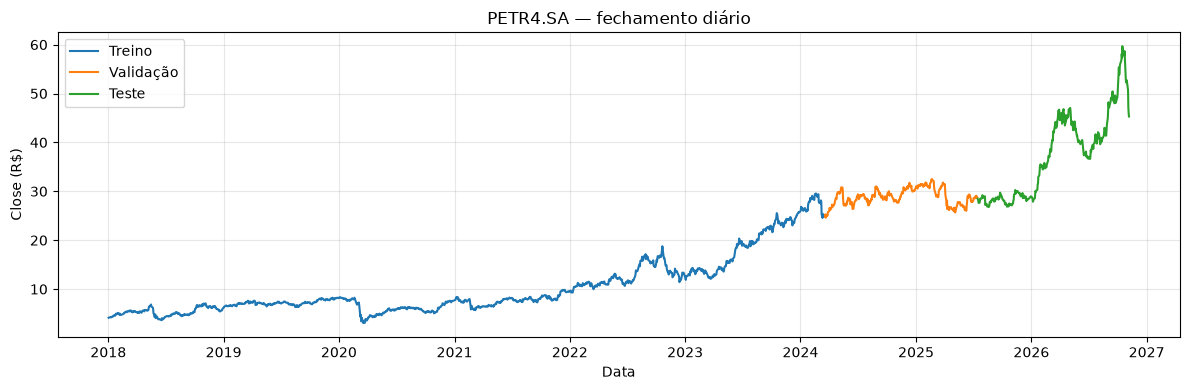

In [4]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(train["date"], train["close"], label="Treino", color="#1f77b4")
ax.plot(val["date"], val["close"], label="Validação", color="#ff7f0e")
ax.plot(test["date"], test["close"], label="Teste", color="#2ca02c")
ax.set_title(f"{TICKER} — fechamento diário")
ax.set_xlabel("Data")
ax.set_ylabel("Close (R$)")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

O gráfico deve mostrar três blocos **em sequência no tempo**, não misturados. Próximo passo acadêmico: `notebooks/02_treino_e_avaliacao.ipynb`.